# Order-balanced re-analysis of the bimodal experiment

Sessions run before 12 June 2025 mis-timed the visual test whenever it was in the second interval. The 17 ms timing criterion removed almost all of those test-second trials, while the test-first trials of the same sessions were kept. The make-up sessions were shorter, and their order was again random. So 7 of the 11 participants (hh, ip, ln2, mh, ml, qs, sx) have far fewer test-second than test-first trials in some conflict conditions.

Several participants also prefer one interval over the other. When the two orders are balanced, that interval bias cancels out of the PSE. When they are not, it leaks into the PSE.

This notebook compares two data sets:

| Data set | Contents |
|---|---|
| **All trials (corrected)** | The published trial set, rebuilt from the raw session files. The duplicated make-up sessions in `data/mh_all.csv` and `data/ml_all.csv` are fixed, and mh's 11 June test-first trials are included. This is identical to `av_dur_data/all_bimodal.csv`. |
| **Order-balanced** | Only correctly timed sessions (code version C). Within every participant × noise × conflict cell, the larger order group is randomly subsampled down to the size of the smaller one (seed 0). |

For each data set the notebook gives per-cell psychometric fits (PSE vs. conflict), plus quick fits of the three main models with sensory noise fixed from the unimodal tasks. Heavy computations are cached in `balanced_order_analysis/` by `python balanced_order_tools.py`.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import seaborn as sns

from plot_style import *          # shared rcParams + seaborn theme
import balanced_order_tools as bot

OUT = bot.OUT_DIR
FIG_DIR = OUT / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

CODES = list(bot.PARTICIPANTS)
NOISE_LABELS = {0.1: 'Low auditory noise', 1.2: 'High auditory noise'}
DATASET_LABELS = {'full': 'All trials (corrected)', 'balanced': 'Order-balanced'}
MODEL_ORDER = ['Forced fusion', 'Causal inference', 'Probabilistic cue switching']
MODEL_COLORS = {'Forced fusion': '#7F7F7F',
                'Causal inference': '#4C78A8',
                'Probabilistic cue switching': '#F58518'}
DATA_STYLE = {
    'full': dict(marker='o', mfc='white', mec='0.5', color='0.5', ls='--', lw=1.5, ms=7,
                 label=DATASET_LABELS['full']),
    'balanced': dict(marker='o', color='black', ls='-', lw=2, ms=7,
                     label=DATASET_LABELS['balanced']),
}

def plabel(c):
    return f"{bot.PARTICIPANTS[c]} {c}" + (' *' if c in bot.AFFECTED else '')

def save(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png')
    fig.savefig(FIG_DIR / f'{name}.pdf')

## 1. Trial table rebuilt from the raw session files

Each included session is labelled with its code version:

- **A:** half bias correction on the test-second visual test (2–5 June 2025).
- **B:** the test-second visual test ignored the test duration (7–11 June 2025).
- **C:** correct code (from 12 June 2025).

Every participant's sessions go through `loadData`, so the 17 ms timing criterion and the derived columns are exactly those of the published analysis. The rebuilt table must match `av_dur_data/all_bimodal.csv`.

In [2]:
trials = bot.build_trials()
check = bot.validate_against_shared(trials)
print('Rebuilt table matches av_dur_data/all_bimodal.csv for every participant x order:',
      bool(check['match'].all()))
check.unstack('order')

Rebuilt table matches av_dur_data/all_bimodal.csv for every participant x order: True


rebuilt       shared       match      
order             1.0   2.0    1.0   2.0   1.0   2.0
participantID                                       
P01              1080  1075   1080  1075  True  True
P02              1106  1120   1106  1120  True  True
P03              1229   185   1229   185  True  True
P04              1240   916   1240   916  True  True
P07              1215   779   1215   779  True  True
P08              1197   955   1197   955  True  True
P09              1402   540   1402   540  True  True
P10              1100  1056   1100  1056  True  True
P11              1088  1083   1088  1083  True  True
P12              1297   942   1297   942  True  True
P13              1308   763   1308   763  True  True

In [3]:
sessions = (trials.groupby(['participantID', 'code', 'session', 'codeVersion', 'sessionNote'])['order']
            .value_counts().unstack(fill_value=0)
            .rename(columns={1: 'test first kept', 2: 'test second kept'})
            .reset_index())
sessions

order,participantID,code,session,codeVersion,sessionNote,test first kept,test second kept
0,P02,dt,2025-06-12_13h17.06,C,aborted start,7,7
1,P02,dt,2025-06-13_15h12.38,C,1D2U staircase removed by hand,172,164
2,P02,dt,2025-06-14_15h11.25,C,1D2U staircase re-run,155,181
3,P03,hh,2025-06-13_12h36.28,C,make-up,105,123
4,P03,hh,2025-06-13_12h56.33,C,make-up,58,62
5,P04,ip,2025-06-17_13h31.09,C,make-up; bias corrections swapped between nois...,147,165
6,P07,ln2,2025-06-12_13h54.19,C,aborted start,3,7
7,P07,ln2,2025-06-14_15h40.10,C,make-up,142,154
8,P07,ln2,2025-06-14_16h02.00,C,make-up,195,157
9,P08,mh,2025-06-17_14h05.00,C,make-up,138,174


## 2. Order-balanced data set

This drops every session that ran on buggy code (versions A and B), then equalises the two orders within each participant × noise × conflict cell.

Two caveats:

- **hh** loses the −83 and +167 ms conflicts entirely, because that block was never re-run on fixed code.
- **ip**'s 17 June make-up is kept. It is correctly timed and balanced, but it ran with the two noise levels' bias corrections swapped.

In [4]:
balanced = bot.make_balanced(trials, seed=0)
datasets = {'full': trials, 'balanced': balanced}

n_cells = lambda d: d.groupby(['code', 'audNoise', 'conflict_nominal']).ngroups
summary = pd.DataFrame({
    'participant': [plabel(c) for c in CODES],
    'all trials': [int((trials.code == c).sum()) for c in CODES],
    'test-second share (all)': [round((trials[trials.code == c].order == 2).mean(), 2) for c in CODES],
    'balanced trials': [int((balanced.code == c).sum()) for c in CODES],
    'kept %': [round(100 * (balanced.code == c).sum() / (trials.code == c).sum()) for c in CODES],
    'cells (all / balanced)': [f"{n_cells(trials[trials.code == c])} / {n_cells(balanced[balanced.code == c])}"
                               for c in CODES],
})
print(f"All trials: {len(trials):,}   balanced: {len(balanced):,} ({100 * len(balanced) / len(trials):.0f}% kept)")
print('* = affected by the order imbalance')
summary

All trials: 22,676   balanced: 17,156 (76% kept)
* = affected by the order imbalance


,participant,all trials,test-second share (all),balanced trials,kept %,cells (all / balanced)
0,P01 as,2155,0.50,2016,94,14 / 14
1,P02 dt,2226,0.50,2082,94,14 / 14
2,P03 hh *,1414,0.13,300,21,14 / 10
3,P04 ip *,2156,0.42,1742,81,14 / 14
4,P07 ln2 *,1994,0.39,1484,74,14 / 14
5,P08 mh *,2152,0.44,1700,79,14 / 14
6,P09 ml *,1942,0.28,686,35,14 / 14
7,P10 mt,2156,0.49,2000,93,14 / 14
8,P11 oy,2171,0.50,2042,94,14 / 14
9,P12 qs *,2239,0.42,1786,80,14 / 14


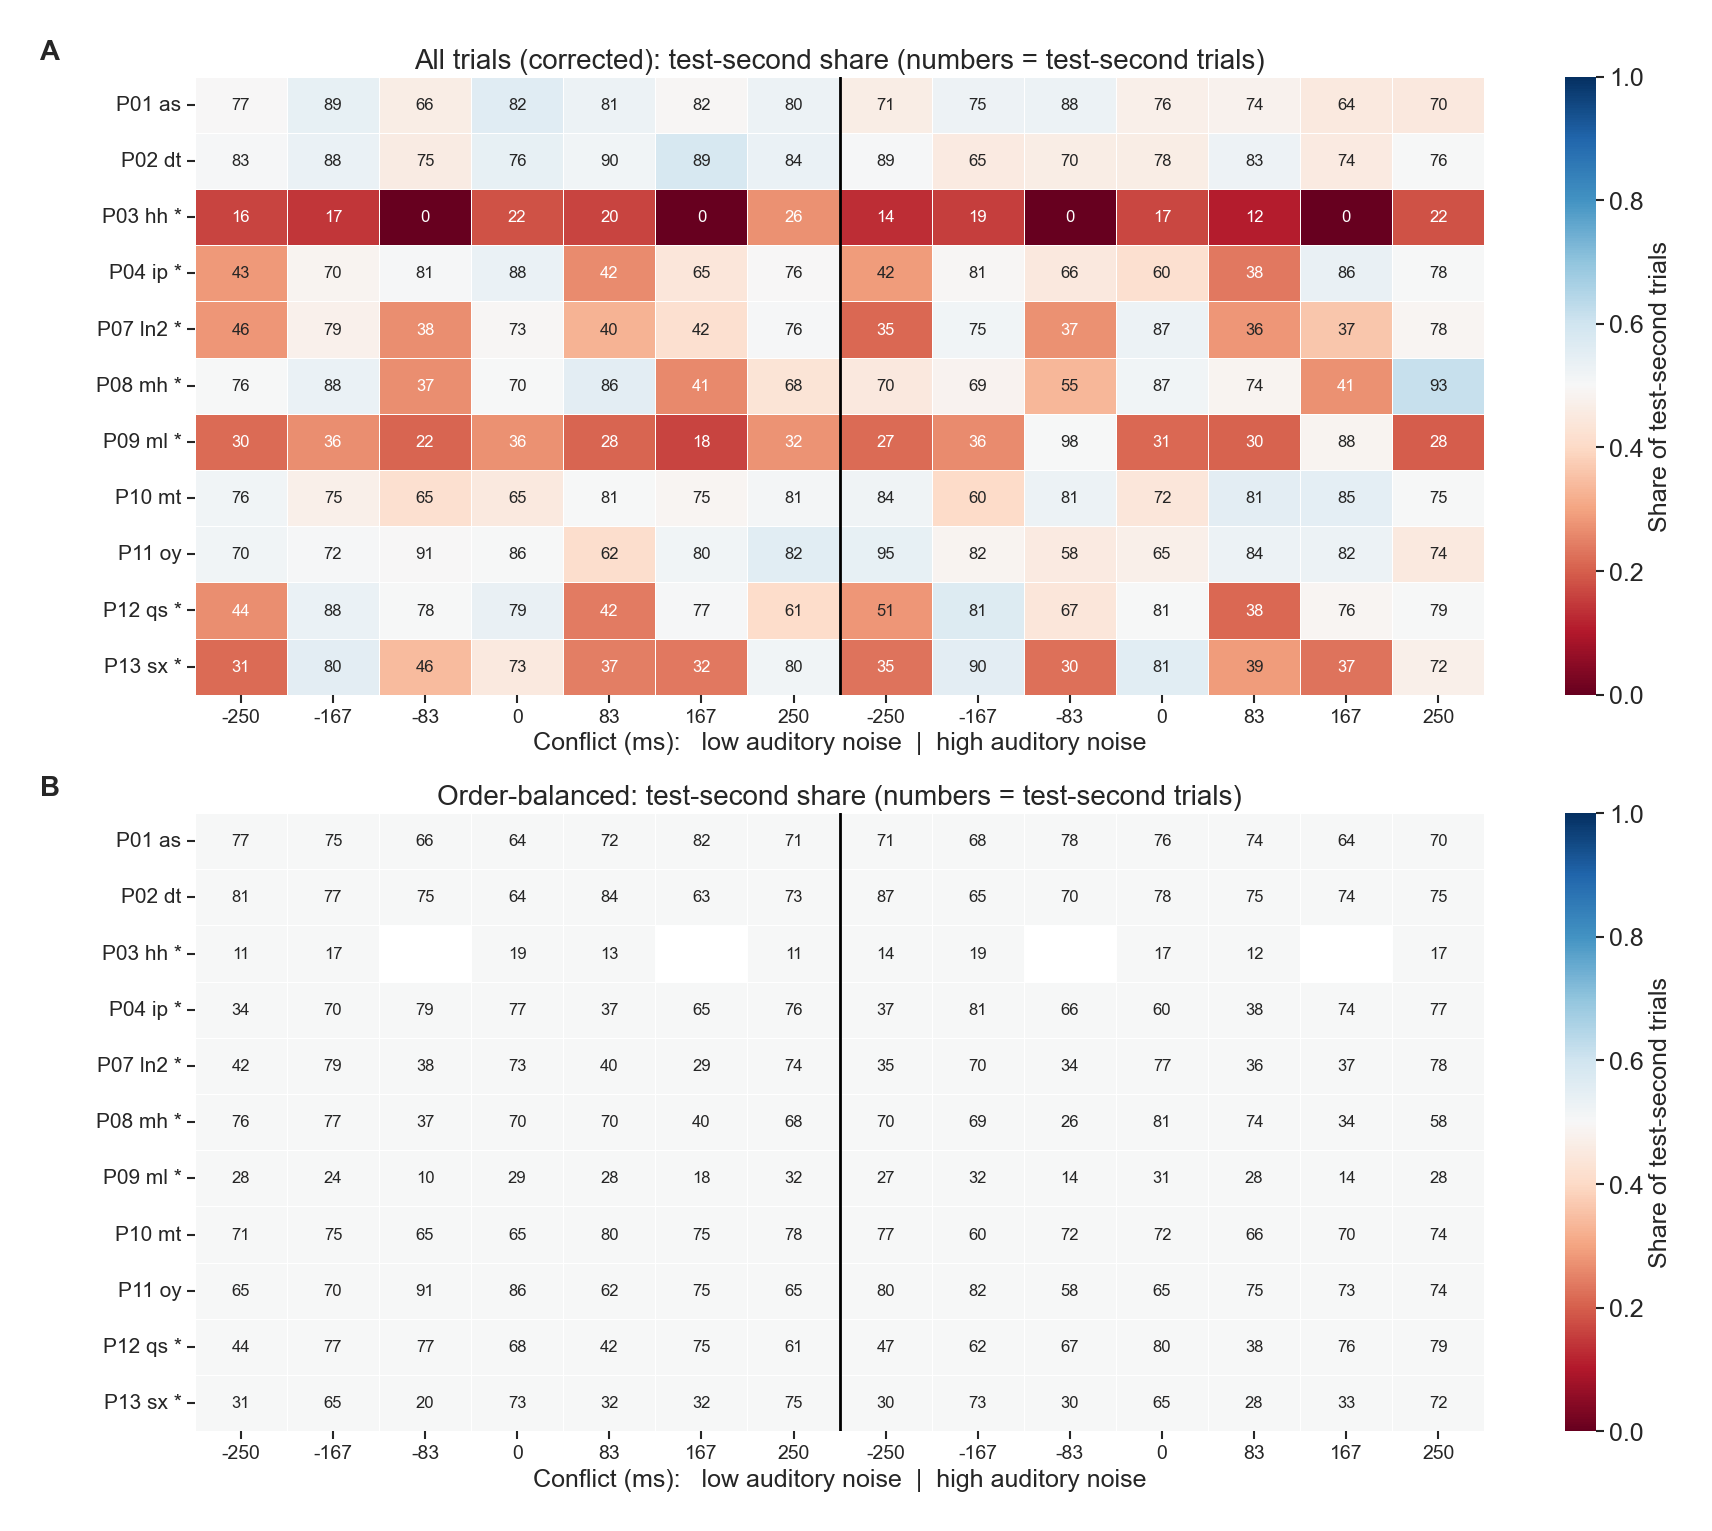

In [5]:
def share_table(d):
    t = (d.assign(t2=(d.order == 2))
          .groupby(['code', 'audNoise', 'conflict_nominal'])
          .agg(share=('t2', 'mean'), n2=('t2', 'sum')))
    share = t['share'].unstack(['audNoise', 'conflict_nominal']).reindex(CODES)
    n2 = t['n2'].unstack(['audNoise', 'conflict_nominal']).reindex(CODES)
    return share, n2

fig, axes = plt.subplots(2, 1, figsize=(18, 15))
for ax, (name, d) in zip(axes, datasets.items()):
    share, n2 = share_table(d)
    cols = [(nz, c) for nz in (0.1, 1.2) for c in bot.NOMINAL_CONFLICTS]
    share, n2 = share.reindex(columns=cols), n2.reindex(columns=cols)
    annot = n2.map(lambda v: '' if pd.isna(v) else f'{int(v)}')
    sns.heatmap(share, ax=ax, cmap='RdBu', vmin=0, vmax=1, center=0.5, annot=annot, fmt='',
                annot_kws={'fontsize': 12}, linewidths=0.5, linecolor='white',
                cbar_kws={'label': 'Share of test-second trials'})
    ax.set_xticklabels([f'{int(round(c * 1000))}' for _, c in cols], rotation=0, fontsize=14)
    ax.set_yticklabels([plabel(c) for c in CODES], rotation=0, fontsize=15)
    ax.axvline(7, color='black', lw=2)
    ax.set_xlabel('Conflict (ms):   low auditory noise  |  high auditory noise', fontsize=FONT_SIZE_LABEL)
    ax.set_ylabel('')
    ax.set_title(f'{DATASET_LABELS[name]}: test-second share (numbers = test-second trials)',
                 fontsize=FONT_SIZE_TITLE)
add_panel_labels(axes, x=-0.12, y=1.06)
fig.tight_layout()
save(fig, 'order_share_heatmap')
plt.show()

## 3. PSE vs. conflict

These are per-cell psychometric fits (lognormal PF, free μ, σ and λ per participant × noise × conflict), reported as the PSE shift in ms relative to the 500 ms standard. The dotted diagonal marks complete visual capture (PSE = conflict).

Model predictions come from the quick fits in Section 4: each fitted model is simulated on a grid of test durations, and a PF is fitted to the predicted curve. If `balanced_order_analysis/` has no cached fits yet, the model lines are left out.

In [6]:
pse_path = OUT / 'pse_fits.csv'
pse = (pd.read_csv(pse_path) if pse_path.exists()
       else pd.concat([bot.fit_pse(d, n) for n, d in datasets.items()], ignore_index=True))

mpse_path = OUT / 'model_pse.csv'
mpse = pd.read_csv(mpse_path) if mpse_path.exists() else None
print('model predictions available:', mpse is not None)

def group_mean(df, keys):
    g = df.groupby(keys)['pse_ms'].agg(['mean', 'std', 'count']).reset_index()
    g['sem'] = g['std'] / np.sqrt(g['count'])
    return g

pse_group = group_mean(pse, ['dataset', 'audNoise', 'conflict_ms'])
model_group = group_mean(mpse, ['dataset', 'modelLabel', 'audNoise', 'conflict_ms']) if mpse is not None else None

model predictions available: True


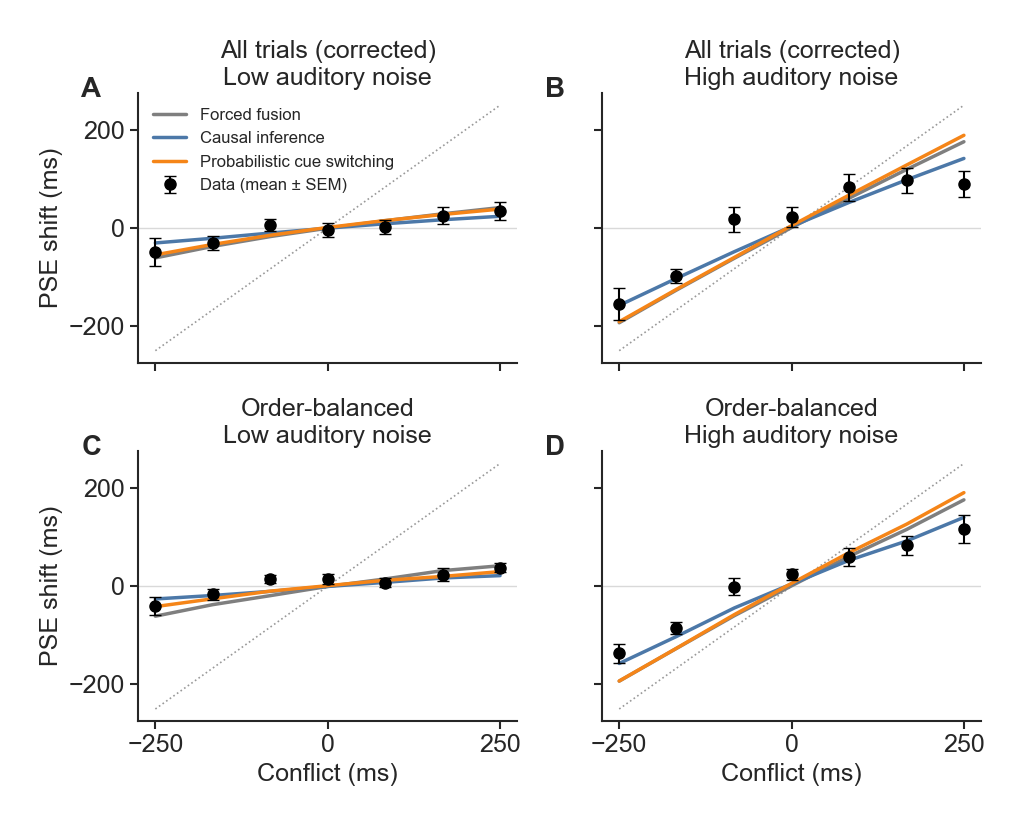

n per point = participants with a PSE in that cell; in the balanced set hh has no −83/+167 ms cells.


In [7]:
def reference_lines(ax):
    ax.axhline(0, color='0.85', lw=1, zorder=0)
    ax.plot([-250, 250], [-250, 250], ls=':', color='0.6', lw=1.2, zorder=0)
    ax.set_xticks([-250, 0, 250])

fig, axes = plt.subplots(2, 2, figsize=figsize_panel(2, 2), sharex=True, sharey=True)
for i, ds in enumerate(['full', 'balanced']):
    for j, noise in enumerate([0.1, 1.2]):
        ax = axes[i, j]
        reference_lines(ax)
        if model_group is not None:
            for label in MODEL_ORDER:
                m = model_group[(model_group.dataset == ds) & (model_group.audNoise == noise)
                                & (model_group.modelLabel == label)].sort_values('conflict_ms')
                ax.plot(m.conflict_ms, m['mean'], color=MODEL_COLORS[label], lw=2.5, label=label)
        g = pse_group[(pse_group.dataset == ds) & (pse_group.audNoise == noise)].sort_values('conflict_ms')
        ax.errorbar(g.conflict_ms, g['mean'], yerr=g['sem'], fmt='o', color='black', ms=8,
                    capsize=4, lw=1.5, label='Data (mean ± SEM)', zorder=3)
        ax.set_title(f"{DATASET_LABELS[ds]}\n{NOISE_LABELS[noise]}", fontsize=FONT_SIZE_LABEL)
        sns.despine(ax=ax)
for ax in axes[1]:
    ax.set_xlabel('Conflict (ms)')
for ax in axes[:, 0]:
    ax.set_ylabel('PSE shift (ms)')
axes[0, 0].legend(fontsize=FONT_SIZE_LEGEND - 6, frameon=False, loc='upper left')
add_panel_labels(axes.ravel())
fig.tight_layout()
save(fig, 'pse_vs_conflict_group')
plt.show()
print('n per point = participants with a PSE in that cell; in the balanced set hh has no −83/+167 ms cells.')

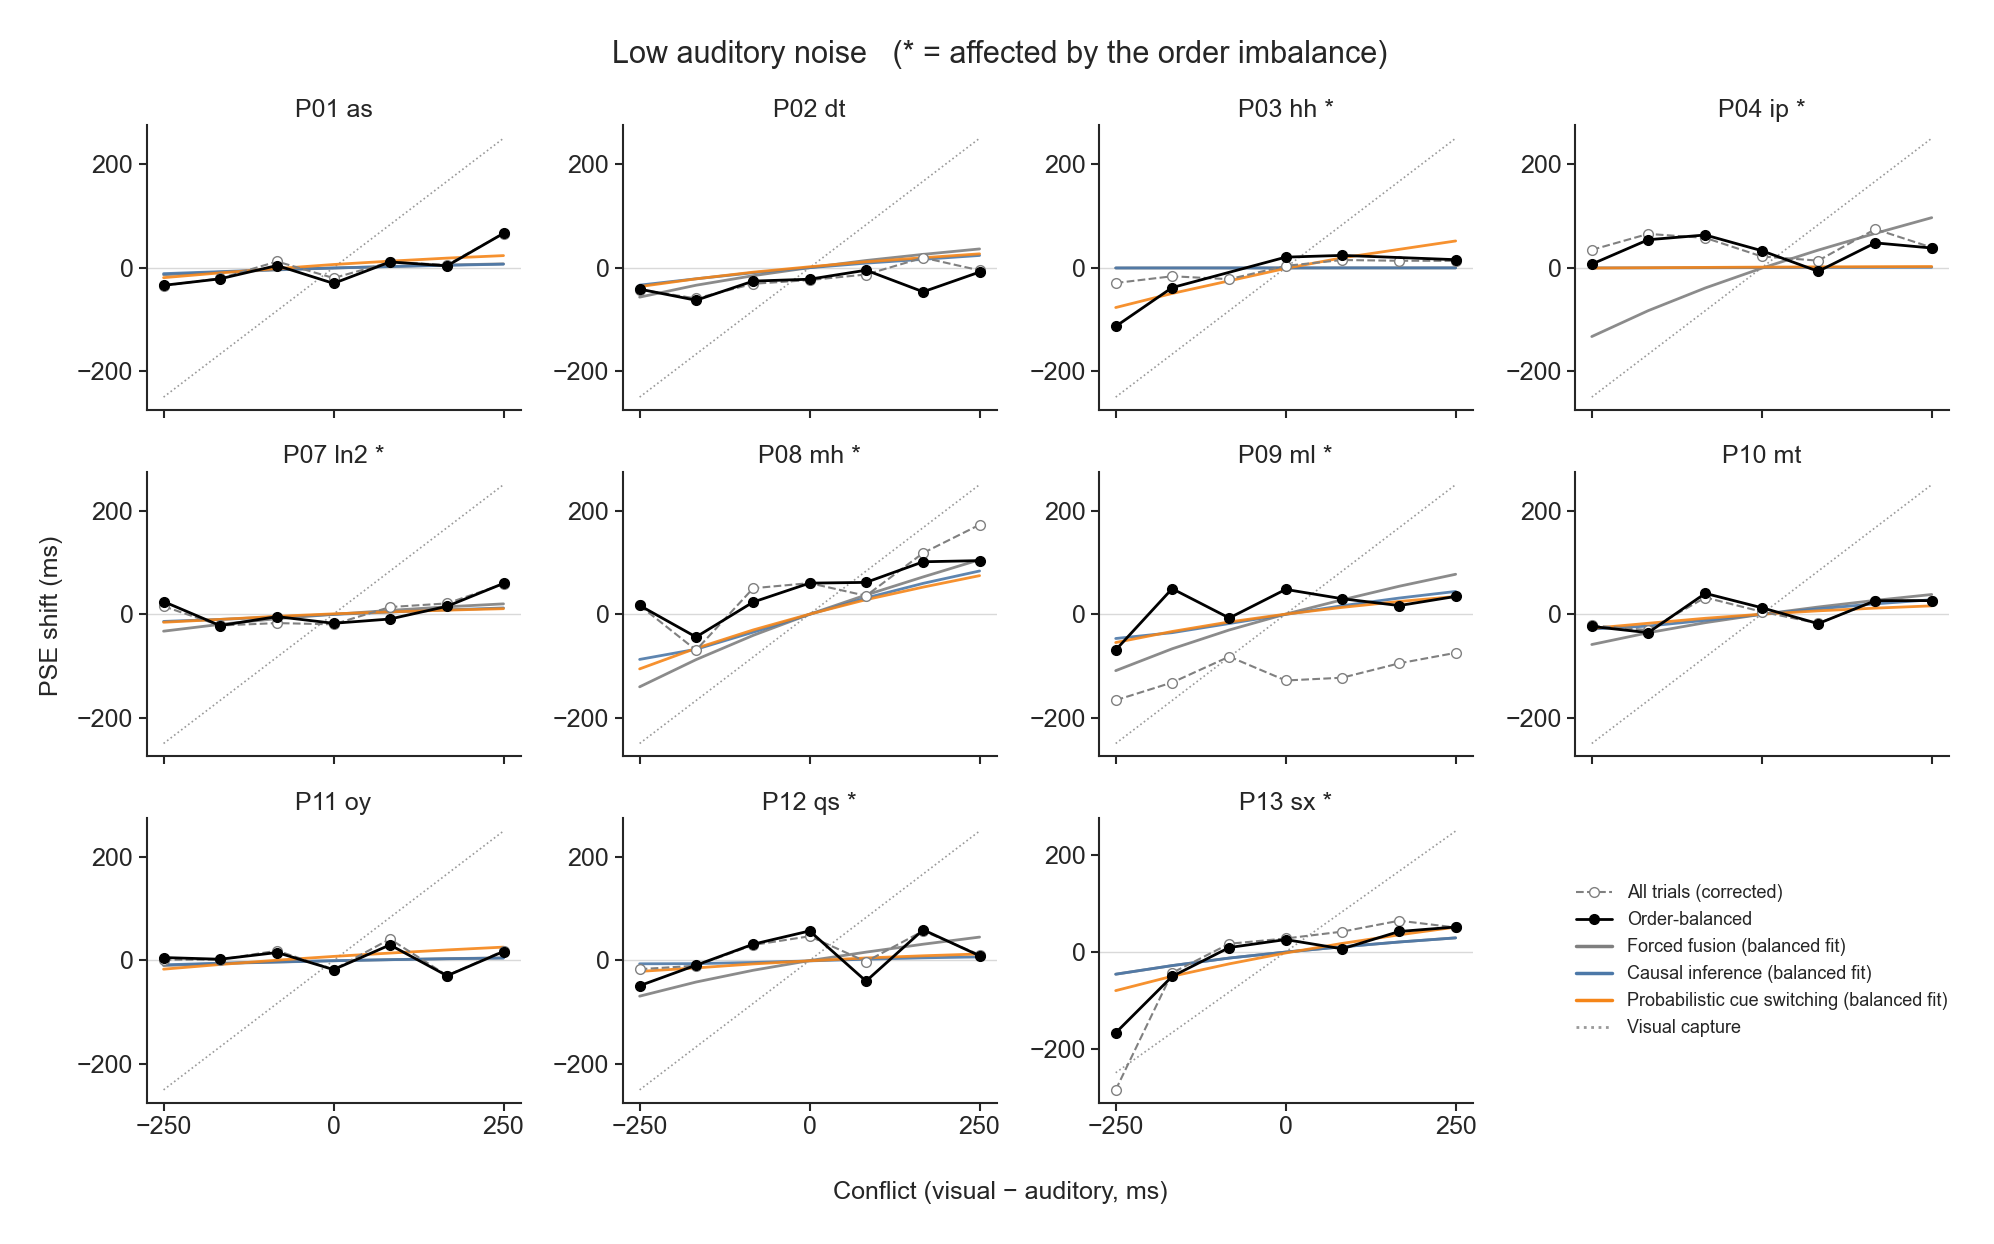

In [8]:
def participant_grid(noise, name):
    fig, axes = plt.subplots(3, 4, figsize=figsize_panel(4, 3), sharex=True)
    axes = axes.ravel()
    for ax, c in zip(axes, CODES):
        reference_lines(ax)
        if mpse is not None:
            for label in MODEL_ORDER:
                m = mpse[(mpse.dataset == 'balanced') & (mpse.code == c) & (mpse.audNoise == noise)
                         & (mpse.modelLabel == label)].sort_values('conflict_ms')
                ax.plot(m.conflict_ms, m.pse_ms, color=MODEL_COLORS[label], lw=2, alpha=0.9)
        for ds in ['full', 'balanced']:
            d = pse[(pse.dataset == ds) & (pse.code == c) & (pse.audNoise == noise)].sort_values('conflict_ms')
            ax.plot(d.conflict_ms, d.pse_ms, **{k: v for k, v in DATA_STYLE[ds].items() if k != 'label'})
        ax.set_title(plabel(c), fontsize=FONT_SIZE_LABEL)
        sns.despine(ax=ax)
    legend_ax = axes[-1]
    legend_ax.axis('off')
    handles = [Line2D([], [], **DATA_STYLE['full']), Line2D([], [], **DATA_STYLE['balanced'])]
    if mpse is not None:
        handles += [Line2D([], [], color=MODEL_COLORS[l], lw=2.5, label=f'{l} (balanced fit)')
                    for l in MODEL_ORDER]
    handles += [Line2D([], [], ls=':', color='0.6', label='Visual capture')]
    legend_ax.legend(handles=handles, loc='center', frameon=False, fontsize=FONT_SIZE_LEGEND - 5)
    fig.supxlabel('Conflict (visual − auditory, ms)', fontsize=FONT_SIZE_LABEL)
    fig.supylabel('PSE shift (ms)', fontsize=FONT_SIZE_LABEL)
    fig.suptitle(f'{NOISE_LABELS[noise]}   (* = affected by the order imbalance)', fontsize=FONT_SIZE_SUPER)
    fig.tight_layout()
    save(fig, name)
    plt.show()

participant_grid(0.1, 'pse_vs_conflict_participants_lowNoise')

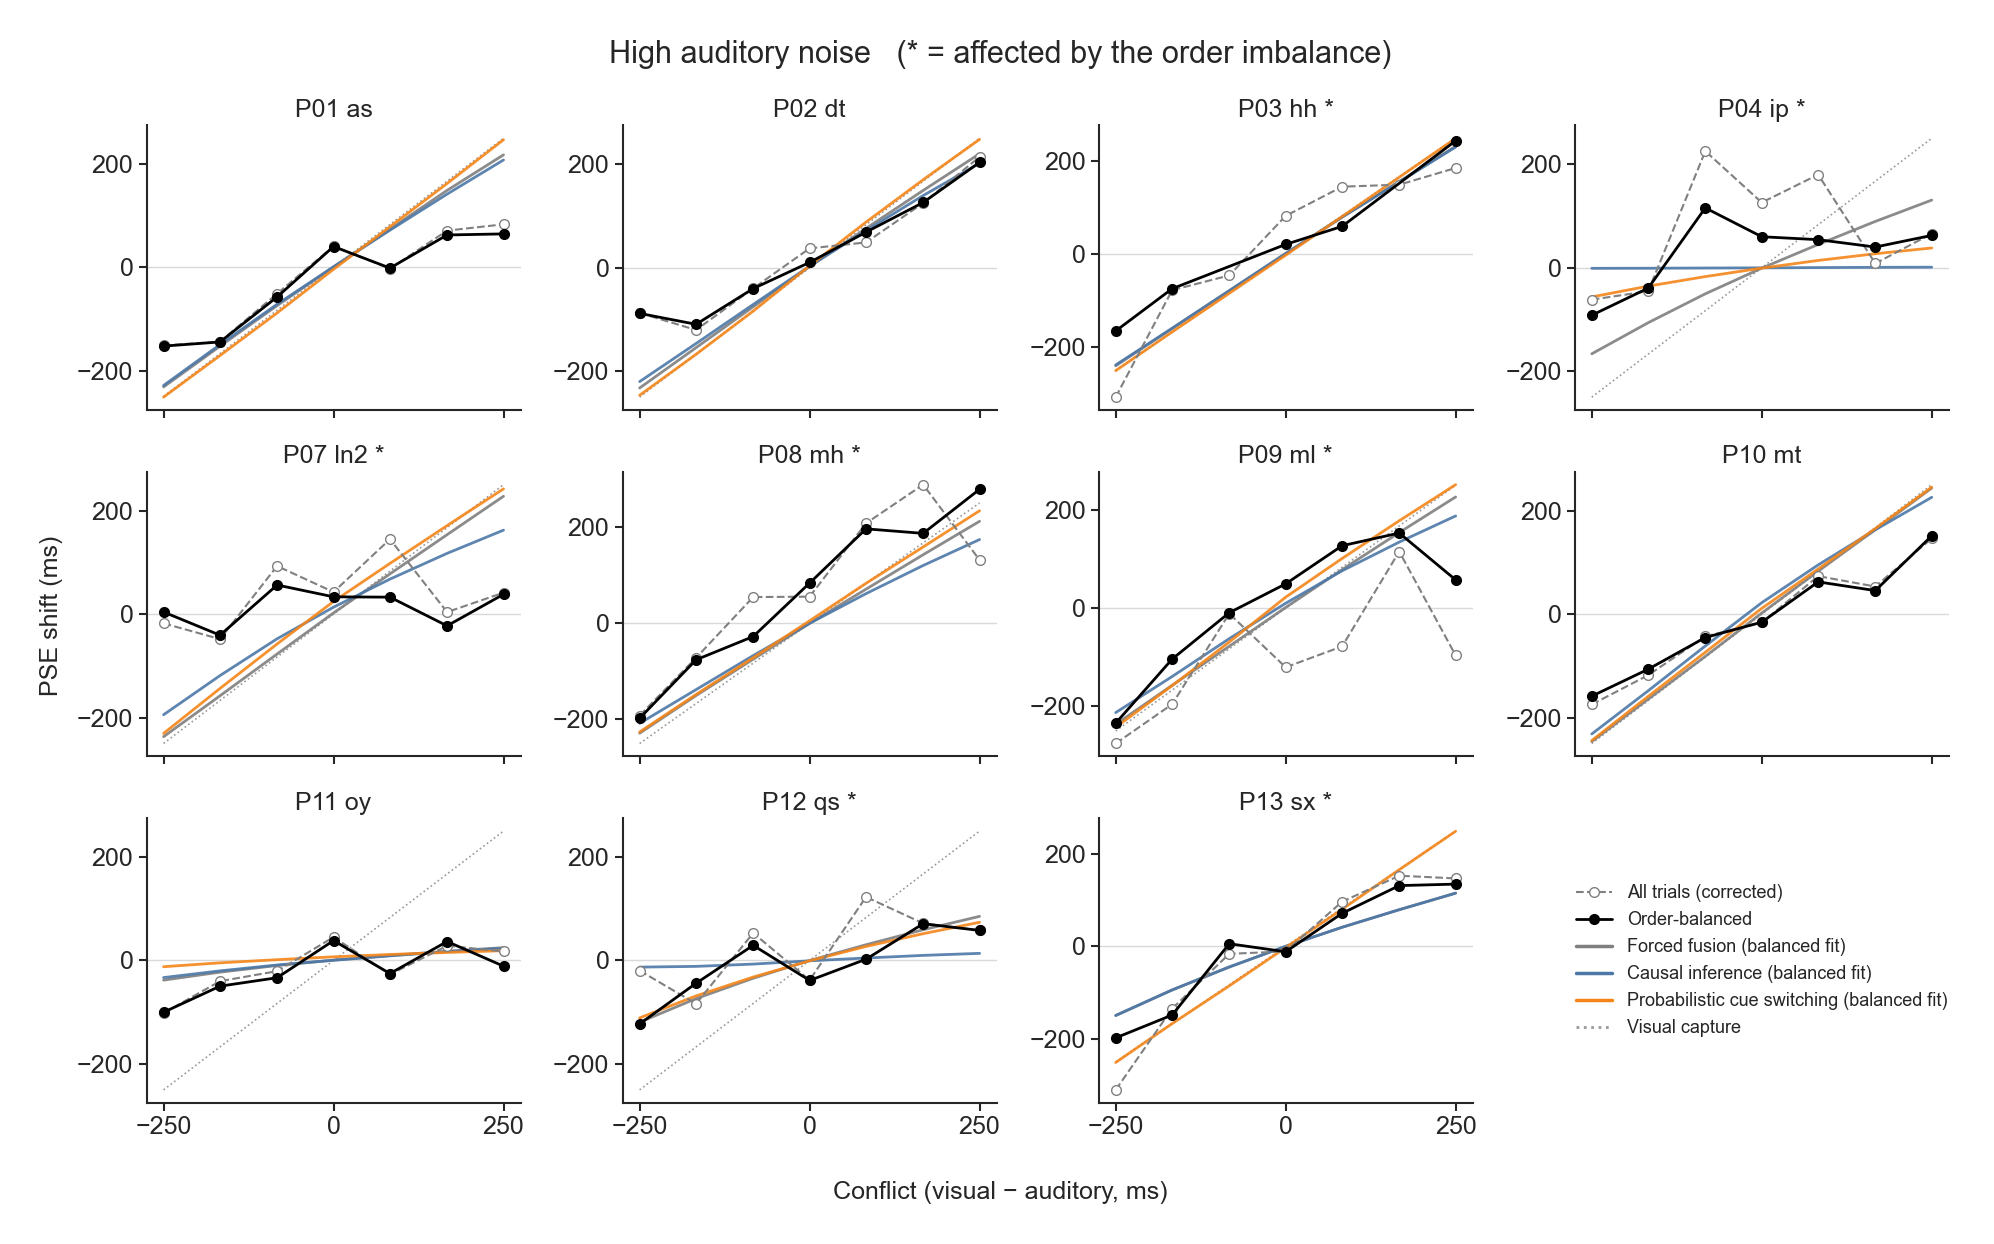

In [9]:
participant_grid(1.2, 'pse_vs_conflict_participants_highNoise')

### How much did each participant's PSEs move?

These are the balanced minus all-trials values. The slope is the least-squares slope of PSE (ms) on conflict (ms): 0 = pure audition, 1 = complete visual capture.

In [10]:
both = pse.pivot_table(index=['code', 'audNoise', 'conflict_ms'], columns='dataset', values='pse_ms').dropna()
both['diff'] = both['balanced'] - both['full']

def slope(d):
    d = d.dropna(subset=['pse_ms'])
    return np.polyfit(d.conflict_ms, d.pse_ms, 1)[0] if len(d) >= 3 else np.nan

slopes = (pse.groupby(['dataset', 'code', 'audNoise']).apply(slope).rename('slope')
          .unstack('dataset').reset_index())
change = (both.groupby(['code', 'audNoise'])['diff']
          .agg(mean_abs_change_ms=lambda x: x.abs().mean(), max_abs_change_ms=lambda x: x.abs().max())
          .reset_index().merge(slopes, on=['code', 'audNoise']))
change['participant'] = change['code'].map(plabel)
change['noise'] = change['audNoise'].map({0.1: 'low', 1.2: 'high'})
change = change.set_index(['participant', 'noise'])[
    ['mean_abs_change_ms', 'max_abs_change_ms', 'full', 'balanced']].rename(
    columns={'full': 'slope all', 'balanced': 'slope balanced'})
change.round(2)

mean_abs_change_ms  max_abs_change_ms  slope all  \
participant noise                                                     
P01 as      low                  3.14              10.29       0.15   
            high                 5.25              18.53       0.51   
P02 dt      low                 12.68              65.92       0.12   
            high                10.14              27.12       0.64   
P03 hh *    low                 26.74              83.79       0.10   
            high                70.28             142.54       0.91   
P04 ip *    low                 14.82              27.56      -0.00   
            high                53.22             125.65       0.19   
P07 ln2 *   low                  7.67              23.11       0.11   
            high                31.01             112.01       0.14   
P08 mh *    low                 23.46              69.25       0.36   
            high                54.27             146.98       0.79   
P09 ml *    low                128.85             181.25       0.13   
            high               100.12             204.84       0.47   
P10 mt      low                  3.38               7.97       0.09   
            high                 7.75              16.03       0.61   
P11 oy      low                  3.07              11.35       0.01   
            high                 9.84              28.44       0.21   
P12 qs *    low                 12.37              37.75       0.08   
            high                41.14             120.24       0.26   
P13 sx *    low                 27.78             118.05       0.54   
            high                29.71             112.58       0.88   

                   slope balanced  
participant noise                  
P01 as      low              0.15  
            high             0.48  
P02 dt      low              0.07  
            high             0.62  
P03 hh *    low              0.25  
            high             0.77  
P04 ip *    low              0.00  
            high             0.24  
P07 ln2 *   low              0.08  
            high             0.05  
P08 mh *    low              0.25  
            high             0.93  
P09 ml *    low              0.12  
            high             0.65  
P10 mt      low              0.09  
            high             0.57  
P11 oy      low             -0.01  
            high             0.19  
P12 qs *    low              0.10  
            high             0.32  
P13 sx *    low              0.36  
            high             0.70

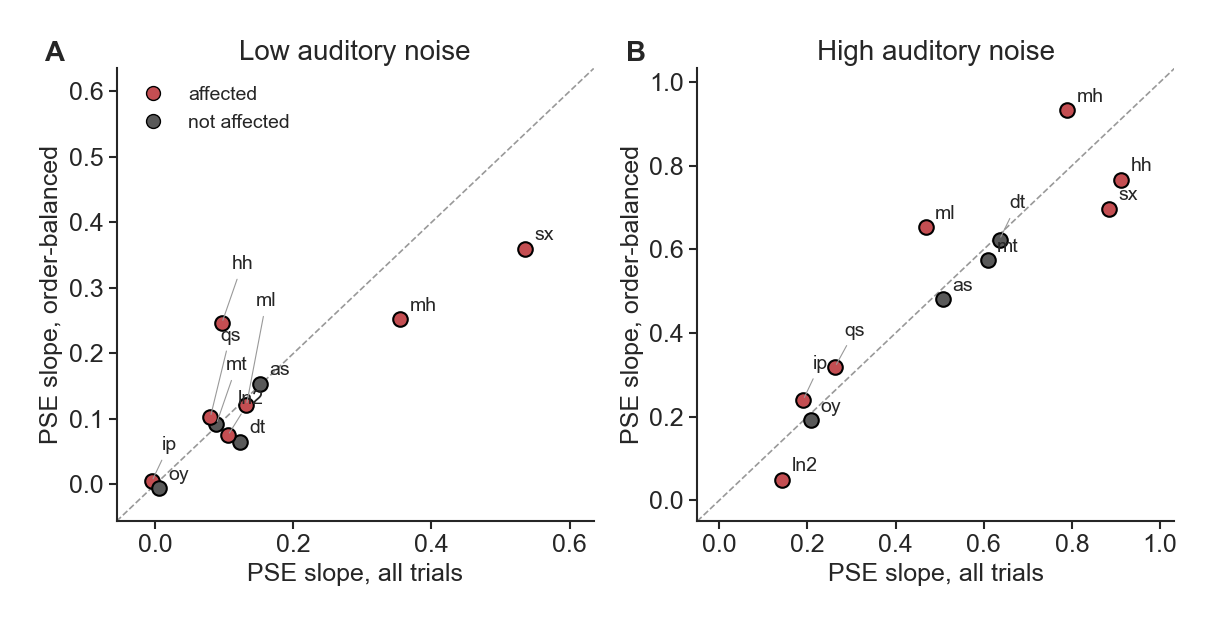

In [11]:
def place_labels(ax, xs, ys, labels, span):
    # stagger labels so neighbouring points stay readable (offsets scale with the axis span)
    step, near = 0.05 * span, 0.09 * span
    placed = []
    for x, y, lab in sorted(zip(xs, ys, labels), key=lambda t: (t[1], t[0])):
        ty = y + 0.01 * span
        while any(abs(x - px) < near and abs(ty - py) < step for px, py in placed):
            ty += step
        placed.append((x, ty))
        ax.annotate(lab, (x, y), xytext=(x + 0.02 * span, ty), textcoords='data', fontsize=14, va='bottom',
                    arrowprops=dict(arrowstyle='-', color='0.6', lw=0.8) if ty - y > 0.04 * span else None)

fig, axes = plt.subplots(1, 2, figsize=figsize_scatter(2, 1))
for ax, (noise, grp) in zip(axes, slopes.groupby('audNoise')):
    vals = grp[['full', 'balanced']].to_numpy()
    lim = [min(vals.min(), 0) - 0.05, vals.max() + 0.1]
    ax.plot(lim, lim, color='0.6', ls='--', lw=1.2, zorder=0)
    for _, r in grp.iterrows():
        affected = r.code in bot.AFFECTED
        ax.scatter(r.full, r.balanced, s=110, color='#C44E52' if affected else '0.35',
                   edgecolor='black', zorder=3)
    place_labels(ax, grp['full'], grp['balanced'], grp['code'], lim[1] - lim[0])
    ax.set(xlim=lim, ylim=lim, xlabel='PSE slope, all trials', ylabel='PSE slope, order-balanced')
    ax.set_title(NOISE_LABELS[noise], fontsize=FONT_SIZE_TITLE)
    sns.despine(ax=ax)
axes[0].legend(handles=[Line2D([], [], marker='o', ls='', color='#C44E52', mec='black', ms=10, label='affected'),
                        Line2D([], [], marker='o', ls='', color='0.35', mec='black', ms=10, label='not affected')],
               frameon=False, fontsize=FONT_SIZE_LEGEND - 4, loc='upper left')
add_panel_labels(axes)
fig.tight_layout()
save(fig, 'pse_slope_full_vs_balanced')
plt.show()

## 4. Quick model fits and AIC

Settings:

- **Models:** forced fusion, causal inference and probabilistic cue switching, as in the published fixed-sensory-noise fits.
- **Fixed sensory noise:** σ from the unimodal fits (÷√2), with one shared lapse rate.
- **Optimiser:** a coarse grid, then bounded Powell, on a common-random-number Monte Carlo likelihood with 1,000 samples per condition.
- **Reported likelihood:** re-evaluated at the best parameters with 5,000 samples. AIC = 2k + 2·nLL.

These are quick fits, so expect about ±2 AIC points of Monte Carlo noise per participant. ΔAIC is relative to forced fusion; negative means better than forced fusion. The balanced data set has fewer trials, so its ΔAICs are naturally smaller in magnitude. Compare signs and rankings, not sizes.

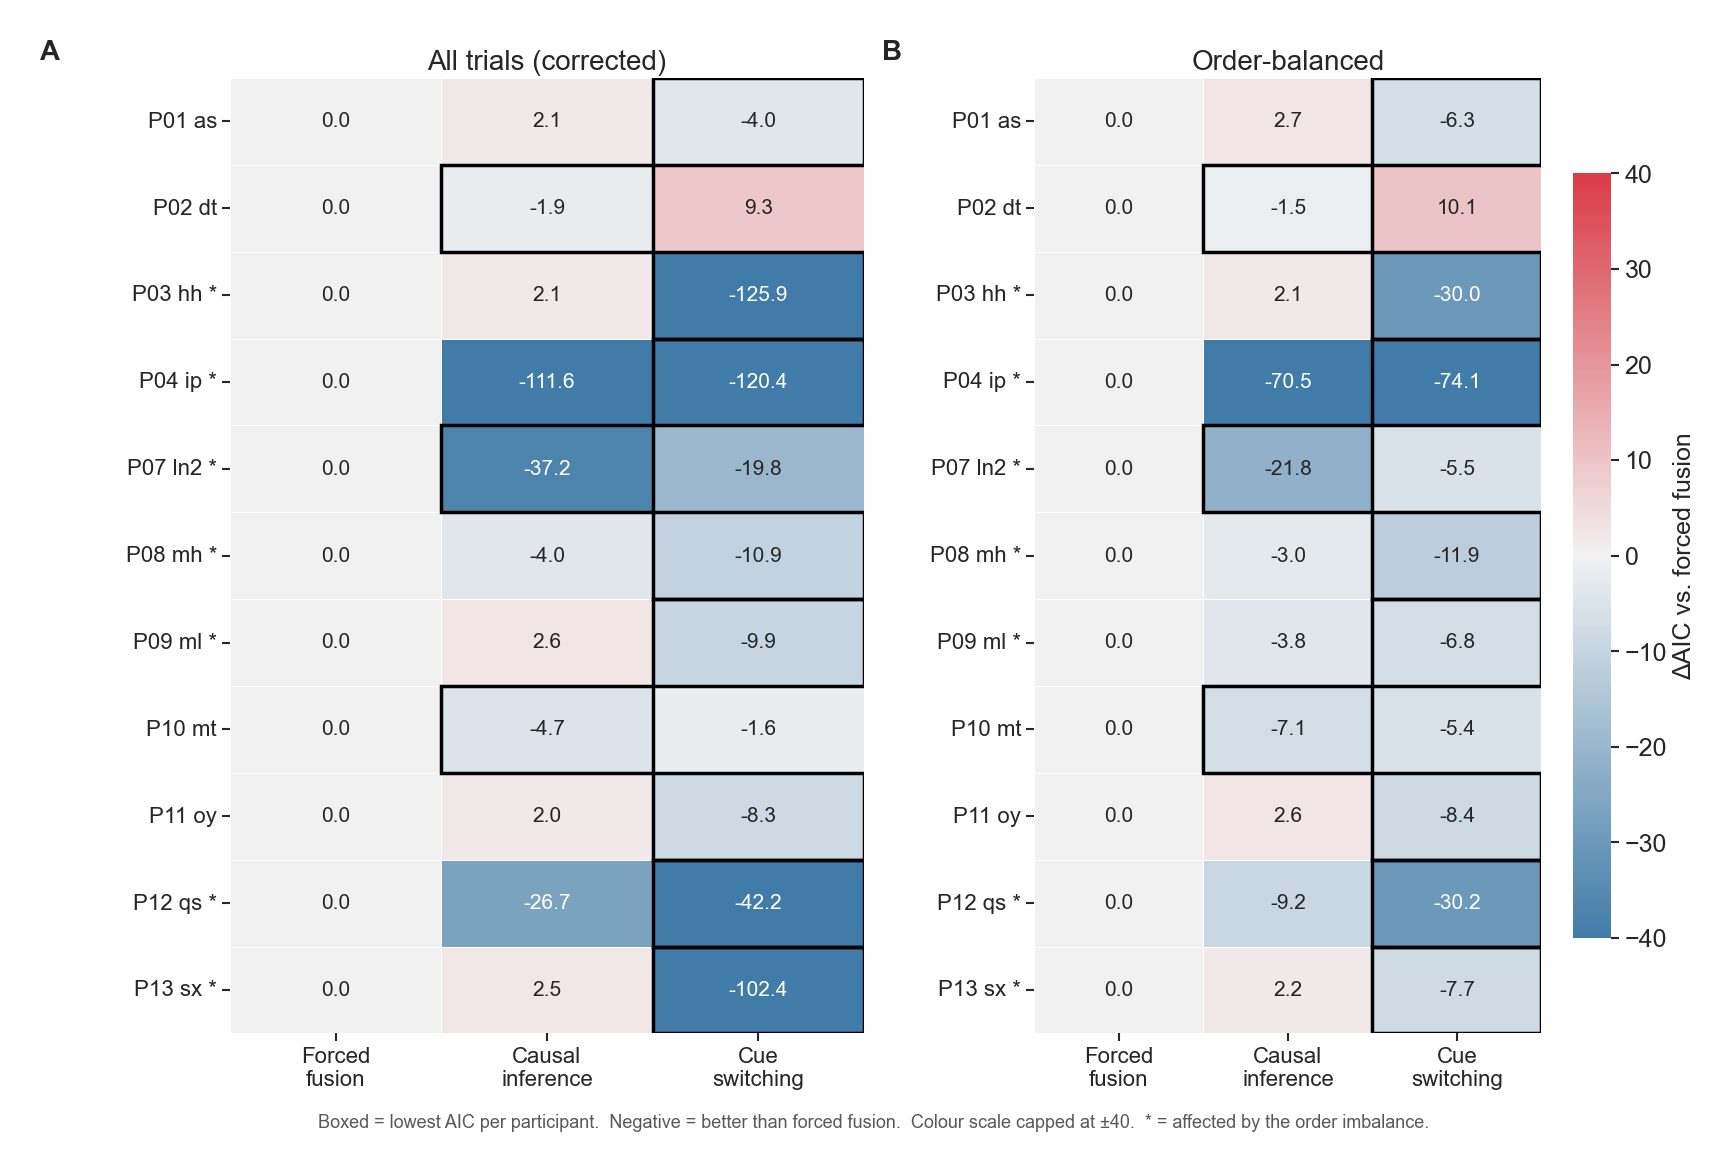

In [12]:
fits = bot.run_model_fits(datasets, n_jobs=7)   # loads the cached fits; fits whatever is missing
fits['modelLabel'] = fits['model'].map(bot.MODEL_LABELS)

def delta_table(ds):
    t = fits[fits.dataset == ds].pivot_table(index='code', columns='modelLabel', values='AIC')
    t = t.reindex(index=CODES, columns=MODEL_ORDER)
    return t.sub(t['Forced fusion'], axis=0)

deltas = {ds: delta_table(ds) for ds in ['full', 'balanced']}
cap = min(max(float(np.nanmax(np.abs(t.to_numpy()))) for t in deltas.values()), 40)

fig, axes = plt.subplots(1, 2, figsize=(17, 11))
for k, (ax, (ds, t)) in enumerate(zip(axes, deltas.items())):
    sns.heatmap(t, ax=ax, annot=True, fmt='.1f', annot_kws={'fontsize': 15},
                cmap=sns.diverging_palette(240, 10, as_cmap=True), center=0, vmin=-cap, vmax=cap,
                linewidths=0.5, linecolor='white', cbar=k == 1,
                cbar_kws={'label': 'ΔAIC vs. forced fusion', 'shrink': 0.8})
    for row, code_ in enumerate(t.index):
        best = int(np.nanargmin(t.loc[code_].to_numpy()))
        ax.add_patch(Rectangle((best, row), 1, 1, fill=False, edgecolor='black', lw=2.5))
    ax.set_xticklabels(['Forced\nfusion', 'Causal\ninference', 'Cue\nswitching'], rotation=0, fontsize=16)
    ax.set_yticklabels([plabel(c) for c in t.index], rotation=0, fontsize=16)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_title(DATASET_LABELS[ds], fontsize=FONT_SIZE_TITLE)
add_panel_labels(axes, x=-0.3, y=1.04)
fig.text(0.5, -0.01, 'Boxed = lowest AIC per participant.  Negative = better than forced fusion.  '
         f'Colour scale capped at ±{cap:.0f}.  * = affected by the order imbalance.',
         ha='center', fontsize=FONT_SIZE_LEGEND - 5, color='0.35')
fig.tight_layout()
save(fig, 'aic_heatmap_full_vs_balanced')
plt.show()

In [13]:
rows = []
for ds, t in deltas.items():
    best = t.idxmin(axis=1)
    for m in MODEL_ORDER:
        rows.append({'data set': DATASET_LABELS[ds], 'model': m,
                     'sum ΔAIC': round(t[m].sum(), 1), 'mean ΔAIC': round(t[m].mean(), 2),
                     'participants best': int((best == m).sum())})
pd.DataFrame(rows).set_index(['data set', 'model'])

sum ΔAIC  mean ΔAIC  \
data set               model                                              
All trials (corrected) Forced fusion                     0.0       0.00   
                       Causal inference               -174.9     -15.90   
                       Probabilistic cue switching    -436.2     -39.65   
Order-balanced         Forced fusion                     0.0       0.00   
                       Causal inference               -107.4      -9.76   
                       Probabilistic cue switching    -176.4     -16.04   

                                                    participants best  
data set               model                                           
All trials (corrected) Forced fusion                                0  
                       Causal inference                             3  
                       Probabilistic cue switching                  8  
Order-balanced         Forced fusion                                0  
                       Causal inference                             3  
                       Probabilistic cue switching                  8

In [14]:
best_full, best_bal = deltas['full'].idxmin(axis=1), deltas['balanced'].idxmin(axis=1)
best = pd.DataFrame({'best (all trials)': best_full, 'best (balanced)': best_bal})
best['changed'] = np.where(best_full != best_bal, 'yes', '')
best.index = [plabel(c) for c in best.index]
best

,best (all trials),best (balanced),changed
P01 as,Probabilistic cue switching,Probabilistic cue switching,
P02 dt,Causal inference,Causal inference,
P03 hh *,Probabilistic cue switching,Probabilistic cue switching,
P04 ip *,Probabilistic cue switching,Probabilistic cue switching,
P07 ln2 *,Causal inference,Causal inference,
P08 mh *,Probabilistic cue switching,Probabilistic cue switching,
P09 ml *,Probabilistic cue switching,Probabilistic cue switching,
P10 mt,Causal inference,Causal inference,
P11 oy,Probabilistic cue switching,Probabilistic cue switching,
P12 qs *,Probabilistic cue switching,Probabilistic cue switching,


## Caveats

- **Quick fits.** They use a grid plus Powell with 1,000 Monte Carlo samples, against BADS with 10 starts and 3,000 samples in the published fits. ΔAICs within about ±3 are within Monte Carlo noise.
- **Free sensory noise not refit.** Only the fixed-sensory-noise set-up is refit here.
- **Balanced data set coverage.** It drops hh's −83/+167 ms cells and leaves hh with 300 trials, so hh's balanced estimates are noisy. It keeps ip's 17 June make-up, which ran with swapped bias corrections.
- **Random subsampling.** The balancing subsamples at random (seed 0). Different seeds change individual PSEs slightly.